# Hoja de Trabajo 6 – Modelación y Simulación (CC2017)

**Grupo 11.** Conjunto $((11-1) \bmod 4)+1 = 3$: $\alpha_{12}=0.6$, $\alpha_{21}=1.5$; $r_1 = 1$, $r_2 = 0.5 + 0.1\,((11-1)\bmod 5) = 0.5$.

Modelo de competencia de Lotka–Volterra:
$$\dot x = r_1 x(1-x-\alpha_{12}y),\qquad \dot y = r_2 y(1-y-\alpha_{21}x)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sympy as sp

np.random.seed(11)   # semilla fija: todas las corridas son reproducibles
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Parámetros del grupo: conjunto = ((g-1) mod 4) + 1,  r2 = 0.5 + 0.1((g-1) mod 5)
g = 11
conjunto = ((g - 1) % 4) + 1
ALPHAS = {1: (0.5, 0.6), 2: (1.4, 1.5), 3: (0.6, 1.5), 4: (1.5, 0.6)}
a12, a21 = ALPHAS[conjunto]
r1 = 1.0
r2 = 0.5 + 0.1 * ((g - 1) % 5)
print(f"g = {g} | conjunto = {conjunto} | a12 = {a12}, a21 = {a21} | r1 = {r1}, r2 = {r2}")

# Estados iniciales de referencia
P = {"P1": (0.05, 0.05), "P2": (0.80, 0.30), "P3": (0.30, 0.80), "P4": (0.60, 0.60)}


def make_f(a12=a12, a21=a21, r1=r1, r2=r2):
    """Campo vectorial f(t, z) del modelo:
       x' = r1 x (1 - x - a12 y),   y' = r2 y (1 - y - a21 x).
    z puede ser (2,) o (2, N) para simular N estados iniciales a la vez."""
    def f(t, z):
        x, y = z
        return np.array([r1 * x * (1 - x - a12 * y), r2 * y * (1 - y - a21 * x)])
    return f


def jac(x, y, a12=a12, a21=a21, r1=r1, r2=r2):
    """Matriz jacobiana J = [[r1(1-2x-a12 y), -r1 a12 x], [-r2 a21 y, r2(1-2y-a21 x)]]."""
    return np.array([[r1 * (1 - 2 * x - a12 * y), -r1 * a12 * x],
                     [-r2 * a21 * y, r2 * (1 - 2 * y - a21 * x)]])


f = make_f()

g = 11 | conjunto = 3 | a12 = 0.6, a21 = 1.5 | r1 = 1.0, r2 = 0.5


## Task 1

In [2]:
# Task 1.1 — Equilibrios. SymPy SOLO verifica la derivación hecha a mano.
xs, ys, A12, A21, R1, R2 = sp.symbols("x y alpha12 alpha21 r1 r2")
F = sp.Matrix([R1 * xs * (1 - xs - A12 * ys), R2 * ys * (1 - ys - A21 * xs)])
for s in sp.solve(list(F), [xs, ys], dict=True):
    print("  (x*, y*) =", (sp.simplify(s[xs]), sp.simplify(s[ys])))

# Equilibrio interior derivado a mano: x* = (1-a12)/(1-a12 a21), y* = (1-a21)/(1-a12 a21)
def interior(a12, a21):
    d = 1 - a12 * a21
    return ((1 - a12) / d, (1 - a21) / d)

EQ = {"E0": (0.0, 0.0), "E1": (1.0, 0.0), "E2": (0.0, 1.0), "E3": interior(a12, a21)}
print("\nCon los parámetros del grupo:")
for k, (xe, ye) in EQ.items():
    fact = "factible" if (xe >= 0 and ye >= 0) else "NO factible"
    print(f"  {k} = ({xe:+.4f}, {ye:+.4f})  ->  {fact}")

  (x*, y*) = (0, 0)
  (x*, y*) = (0, 1)
  (x*, y*) = (1, 0)
  (x*, y*) = ((alpha12 - 1)/(alpha12*alpha21 - 1), (alpha21 - 1)/(alpha12*alpha21 - 1))

Con los parámetros del grupo:
  E0 = (+0.0000, +0.0000)  ->  factible
  E1 = (+1.0000, +0.0000)  ->  factible
  E2 = (+0.0000, +1.0000)  ->  factible
  E3 = (+4.0000, -5.0000)  ->  NO factible


In [3]:
# Task 1.2 — Jacobiana (verificación simbólica) y clasificación de cada equilibrio factible
print("J simbólica =", sp.simplify(F.jacobian([xs, ys])))

def clasificar(tau, det):
    """Clasificación por traza y determinante (plano tau-Delta)."""
    disc = tau**2 - 4 * det
    if det < 0:
        return "silla"
    est = "estable" if tau < 0 else "inestable"
    if disc >= 0:
        return f"nodo {est}"
    return "centro" if tau == 0 else f"foco {est}"

factibles = {k: v for k, v in EQ.items() if v[0] >= 0 and v[1] >= 0}
TD = {}
for k, (xe, ye) in factibles.items():
    J = jac(xe, ye)
    tau, det = np.trace(J), np.linalg.det(J)
    lam, V = np.linalg.eig(J)
    lam, V = np.real_if_close(lam), np.real_if_close(V)   # valores propios reales
    TD[k] = (tau, det)
    print(f"\n{k} = ({xe:g}, {ye:g})   J = {(J.round(4) + 0.0).tolist()}")
    print(f"   tau = {tau:+.4f}  Delta = {det:+.4f}  tau^2-4Delta = {tau**2 - 4*det:+.4f}")
    print(f"   lambda = {np.round(lam, 4)}  ->  {clasificar(tau, det)}")
    for i in range(2):
        print(f"   v(lambda={lam[i]:+.2f}) = {np.round(V[:, i] / np.max(np.abs(V[:, i])), 4)}")

# Solo como referencia: el equilibrio interior (no factible) también es una silla
xe, ye = EQ["E3"]
print(f"\nE3 (no factible): Delta = {np.linalg.det(jac(xe, ye)):+.4f}")

J simbólica = Matrix([[r1*(-alpha12*y - 2*x + 1), -alpha12*r1*x], [-alpha21*r2*y, r2*(-alpha21*x - 2*y + 1)]])

E0 = (0, 0)   J = [[1.0, 0.0], [0.0, 0.5]]
   tau = +1.5000  Delta = +0.5000  tau^2-4Delta = +0.2500
   lambda = [1.  0.5]  ->  nodo inestable
   v(lambda=+1.00) = [1. 0.]
   v(lambda=+0.50) = [0. 1.]

E1 = (1, 0)   J = [[-1.0, -0.6], [0.0, -0.25]]
   tau = -1.2500  Delta = +0.2500  tau^2-4Delta = +0.5625
   lambda = [-1.   -0.25]  ->  nodo estable
   v(lambda=-1.00) = [1. 0.]
   v(lambda=-0.25) = [-0.8  1. ]

E2 = (0, 1)   J = [[0.4, 0.0], [-0.75, -0.5]]
   tau = -0.1000  Delta = -0.2000  tau^2-4Delta = +0.8100
   lambda = [-0.5  0.4]  ->  silla
   v(lambda=-0.50) = [0. 1.]
   v(lambda=+0.40) = [ 1.     -0.8333]

E3 (no factible): Delta = -1.0000


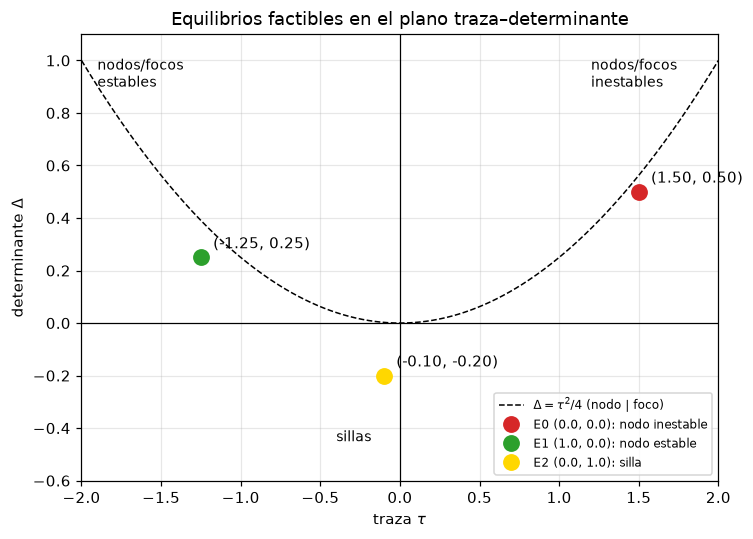

In [4]:
# Task 1.2c — Ubicación de los equilibrios en el plano traza-determinante
fig, ax = plt.subplots(figsize=(7, 5))
tt = np.linspace(-2, 2, 400)
ax.plot(tt, tt**2 / 4, "k--", lw=1, label=r"$\Delta = \tau^2/4$ (nodo | foco)")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
colores = {"E0": "tab:red", "E1": "tab:green", "E2": "gold"}
for k, (tau, det) in TD.items():
    ax.plot(tau, det, "o", ms=10, color=colores[k],
            label=f"{k} {factibles[k]}: {clasificar(tau, det)}")
    ax.annotate(f"({tau:.2f}, {det:.2f})", (tau, det), textcoords="offset points", xytext=(8, 6))
ax.text(-1.9, 0.9, "nodos/focos\nestables", fontsize=9)
ax.text(1.2, 0.9, "nodos/focos\ninestables", fontsize=9)
ax.text(-0.4, -0.45, "sillas", fontsize=9)
ax.set(xlim=(-2, 2), ylim=(-0.6, 1.1), xlabel=r"traza $\tau$", ylabel=r"determinante $\Delta$",
       title="Equilibrios factibles en el plano traza–determinante")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

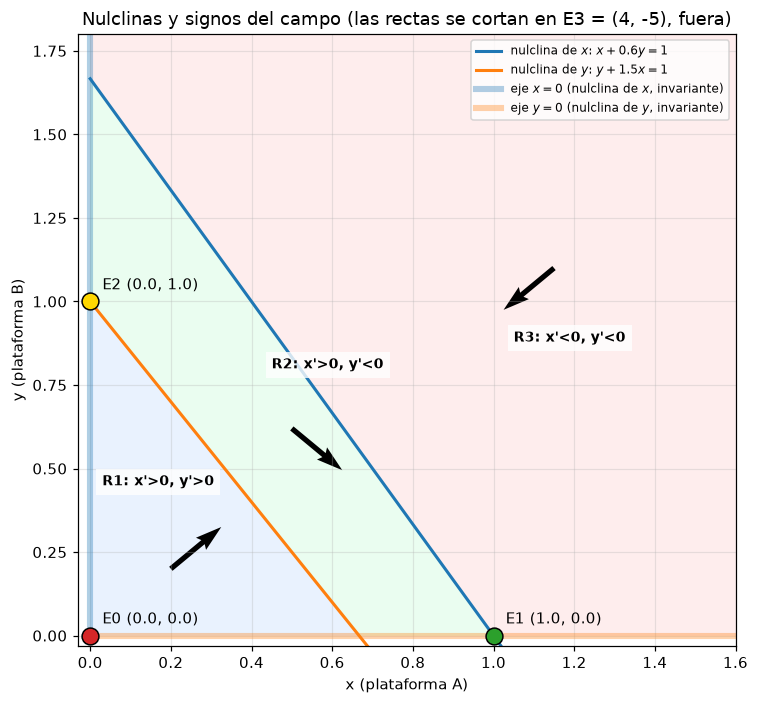

P1 = (0.05, 0.05): x + a12 y = 0.08, y + a21 x = 0.12 -> R1
P2 = (0.8, 0.3): x + a12 y = 0.98, y + a21 x = 1.50 -> R2
P3 = (0.3, 0.8): x + a12 y = 0.78, y + a21 x = 1.25 -> R2
P4 = (0.6, 0.6): x + a12 y = 0.96, y + a21 x = 1.50 -> R2


In [5]:
# Task 1.3a-b — Nulclinas, regiones y dirección del campo en cada región
# Nulclinas de x: x = 0  y  x + a12 y = 1  ->  y = (1 - x)/a12
# Nulclinas de y: y = 0  y  y + a21 x = 1  ->  y = 1 - a21 x
fig, ax = plt.subplots(figsize=(7, 6.5))
x = np.linspace(0, 1.6, 400)
ax.plot(x, (1 - x) / a12, color="tab:blue", lw=2, label=r"nulclina de $x$: $x + 0.6y = 1$")
ax.plot(x, 1 - a21 * x, color="tab:orange", lw=2, label=r"nulclina de $y$: $y + 1.5x = 1$")
ax.plot([0, 0], [0, 1.8], color="tab:blue", lw=4, alpha=0.35, label=r"eje $x=0$ (nulclina de $x$, invariante)")
ax.plot([0, 1.6], [0, 0], color="tab:orange", lw=4, alpha=0.35, label=r"eje $y=0$ (nulclina de $y$, invariante)")

# Regiones: R1 debajo de ambas rectas, R2 entre ellas, R3 encima de ambas
X, Y = np.meshgrid(np.linspace(0, 1.6, 300), np.linspace(0, 1.8, 300))
region = np.where(Y + a21 * X < 1, 1, np.where(X + a12 * Y < 1, 2, 3))
ax.contourf(X, Y, region, levels=[0.5, 1.5, 2.5, 3.5],
            colors=["#dbeafe", "#dcfce7", "#fee2e2"], alpha=0.6)

# Una flecha de signos (sgn x', sgn y') en un punto representativo de cada región
rep = {"R1": ((0.2, 0.2), (0.03, 0.45)), "R2": ((0.5, 0.62), (0.45, 0.80)),
       "R3": ((1.15, 1.1), (1.05, 0.88))}
for nombre, ((px, py), (tx, ty)) in rep.items():
    u, v = np.sign(f(0, np.array([px, py])))
    ax.quiver(px, py, u, v, angles="xy", scale_units="xy", scale=8, width=0.008)
    ax.text(tx, ty, f"{nombre}: x'{'>' if u > 0 else '<'}0, y'{'>' if v > 0 else '<'}0",
            fontsize=9, weight="bold", bbox=dict(fc="white", ec="none", alpha=0.8))

# Intersecciones de nulclinas (equilibrios) dentro del cuadrante
for k, c in [("E0", "tab:red"), ("E1", "tab:green"), ("E2", "gold")]:
    ax.plot(*EQ[k], "o", ms=11, color=c, mec="k", zorder=5)
    ax.annotate(f"{k} {EQ[k]}", EQ[k], textcoords="offset points", xytext=(8, 8))
ax.set(xlim=(-0.03, 1.6), ylim=(-0.03, 1.8), xlabel="x (plataforma A)", ylabel="y (plataforma B)",
       title="Nulclinas y signos del campo (las rectas se cortan en E3 = (4, -5), fuera)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

for k, (px, py) in P.items():
    zona = "R1" if py + a21 * px < 1 else ("R2" if px + a12 * py < 1 else "R3")
    print(f"{k} = {(px, py)}: x + a12 y = {px + a12*py:.2f}, y + a21 x = {py + a21*px:.2f} -> {zona}")

In [6]:
# Task 1.3d — Tiempo característico de recuperación: T_rec = 1 / min|Re(lambda)|
lam = np.real_if_close(np.linalg.eigvals(jac(*EQ["E1"])))
print("lambda en E1 =", lam, "->  T_rec =", 1 / np.min(np.abs(lam.real)))

lambda en E1 = [-1.   -0.25] ->  T_rec = 4.0


In [7]:
# Task 1.4 — Revisión del análisis del compañero (a12 = 1.4, a21 = 1.5, r1 = 1, r2 = 0.8)
pc = dict(a12=1.4, a21=1.5, r1=1.0, r2=0.8)
xc, yc = interior(pc["a12"], pc["a21"])
Jc = jac(xc, yc, **pc)
tau = np.trace(Jc)
det_mal = Jc[0, 0] * Jc[1, 1] + Jc[0, 1] * Jc[1, 0]     # fórmula del compañero (signo +)
det_bien = Jc[0, 0] * Jc[1, 1] - Jc[0, 1] * Jc[1, 0]    # determinante correcto
print(f"(x*, y*) = ({xc:.4f}, {yc:.4f})")
print("J =", Jc.round(4).tolist())
print(f"tau = {tau:.4f}")
print(f"Delta (compañero, J11J22 + J12J21) = {det_mal:+.4f}")
print(f"Delta (correcto,  J11J22 - J12J21) = {det_bien:+.4f}  = np.linalg.det: {np.linalg.det(Jc):+.4f}")
lam_c = np.real_if_close(np.linalg.eigvals(Jc))
print("lambda =", lam_c.round(4), "->", clasificar(tau, det_bien))
for k in ["E1", "E2"]:
    print(f"{k}: lambda = {np.real_if_close(np.linalg.eigvals(jac(*EQ[k], **pc))).round(4)}")

(x*, y*) = (0.3636, 0.4545)
J = [[-0.3636, -0.5091], [-0.5455, -0.3636]]
tau = -0.7273
Delta (compañero, J11J22 + J12J21) = +0.4099
Delta (correcto,  J11J22 - J12J21) = -0.1455  = np.linalg.det: -0.1455
lambda = [ 0.1633 -0.8906] -> silla
E1: lambda = [-1.  -0.4]
E2: lambda = [-0.8 -0.4]


## Task 2

In [8]:
# Task 2.1a — Integradores implementados desde cero (sin solve_ivp)
def euler_step(f, t, z, h):
    """Euler explícito: z_{n+1} = z_n + h f(t_n, z_n)   (orden 1)."""
    return z + h * f(t, z)


def rk4_step(f, t, z, h):
    """Runge-Kutta clásico de orden 4:
       k1 = f(t, z)
       k2 = f(t + h/2, z + h k1/2)
       k3 = f(t + h/2, z + h k2/2)
       k4 = f(t + h,   z + h k3)
       z_{n+1} = z_n + h (k1 + 2 k2 + 2 k3 + k4) / 6"""
    k1 = f(t, z)
    k2 = f(t + h / 2, z + h * k1 / 2)
    k3 = f(t + h / 2, z + h * k2 / 2)
    k4 = f(t + h, z + h * k3)
    return z + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def integrar(step, f, z0, h, T):
    """Aplica 'step' N = T/h veces desde z0. Devuelve los tiempos y la trayectoria."""
    n = int(round(T / h))
    t = np.arange(n + 1) * h
    Z = np.empty((n + 1, len(z0)))
    Z[0] = z0
    for k in range(n):
        Z[k + 1] = step(f, t[k], Z[k], h)
    return t, Z


def euler(f, z0, h, T):
    return integrar(euler_step, f, np.asarray(z0, float), h, T)


def rk4(f, z0, h, T):
    return integrar(rk4_step, f, np.asarray(z0, float), h, T)

In [9]:
# Task 2.1b — Error global en T = 10 desde P2 contra solve_ivp (DOP853, tol = 1e-12)
T = 10.0
z0 = np.array(P["P2"])
ref = solve_ivp(f, (0, T), z0, method="DOP853", rtol=1e-12, atol=1e-12)
z_ref = ref.y[:, -1]
print("Referencia z(10) =", z_ref)

hs = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
# Error = norma euclidiana de la diferencia en el tiempo final: ||z_h(T) - z_ref(T)||
err_eu = np.array([np.linalg.norm(euler(f, z0, h, T)[1][-1] - z_ref) for h in hs])
err_rk = np.array([np.linalg.norm(rk4(f, z0, h, T)[1][-1] - z_ref) for h in hs])
print(f"\n{'h':>8} {'error Euler':>14} {'razón':>7} {'error RK4':>14} {'razón':>7}")
for i, h in enumerate(hs):
    re = err_eu[i - 1] / err_eu[i] if i else np.nan
    rr = err_rk[i - 1] / err_rk[i] if i else np.nan
    print(f"{h:8.4f} {err_eu[i]:14.3e} {re:7.2f} {err_rk[i]:14.3e} {rr:7.2f}")

Referencia z(10) = [0.97824905 0.02704421]

       h    error Euler   razón      error RK4   razón
  0.2000      1.987e-03     nan      4.044e-09     nan
  0.1000      9.919e-04    2.00      2.477e-10   16.33
  0.0500      4.955e-04    2.00      1.527e-11   16.22
  0.0250      2.477e-04    2.00      8.960e-13   17.04
  0.0125      1.238e-04    2.00      7.556e-14   11.86


Pendiente Euler = 1.0010  (teórico 1)
Pendiente RK4   = 3.9526  (teórico 4)
Pendiente RK4 sin h = 0.0125 = 4.0440


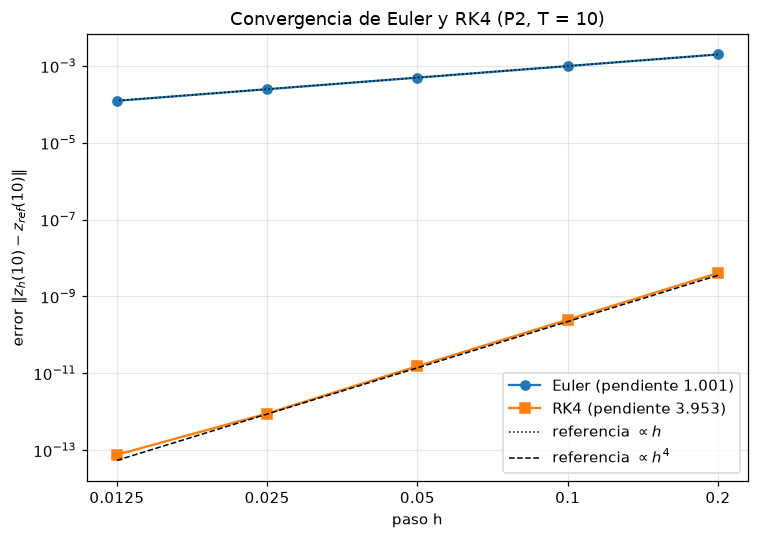

In [10]:
# Task 2.1c — Log-log del error vs h y pendiente por regresión lineal de log(error) = p log(h) + c
p_eu, c_eu = np.polyfit(np.log(hs), np.log(err_eu), 1)
p_rk, c_rk = np.polyfit(np.log(hs), np.log(err_rk), 1)
print(f"Pendiente Euler = {p_eu:.4f}  (teórico 1)")
print(f"Pendiente RK4   = {p_rk:.4f}  (teórico 4)")
p_rk4 = np.polyfit(np.log(hs[:-1]), np.log(err_rk[:-1]), 1)[0]
print(f"Pendiente RK4 sin h = 0.0125 = {p_rk4:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(hs, err_eu, "o-", label=f"Euler (pendiente {p_eu:.3f})")
ax.loglog(hs, err_rk, "s-", label=f"RK4 (pendiente {p_rk:.3f})")
ax.loglog(hs, np.exp(c_eu) * hs**1, "k:", lw=1, label=r"referencia $\propto h$")
ax.loglog(hs, np.exp(c_rk) * hs**4, "k--", lw=1, label=r"referencia $\propto h^4$")
ax.set_xticks(hs, [f"{h:g}" for h in hs])
ax.minorticks_off()
ax.set(xlabel="paso h", ylabel=r"error $\|z_h(10) - z_{ref}(10)\|$",
       title="Convergencia de Euler y RK4 (P2, T = 10)")
ax.legend()
plt.tight_layout()
plt.show()

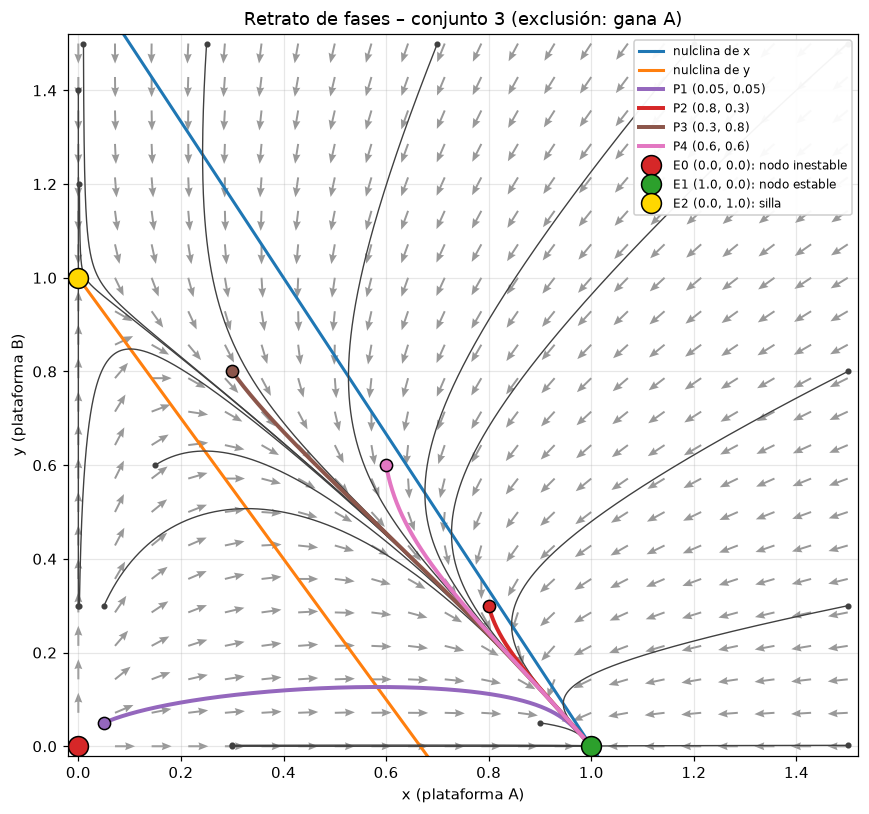

In [11]:
# Task 2.2a-b — Retrato de fases en [0, 1.5]^2 con trayectorias RK4 (h = 0.01, T = 80)
h_pp, T_pp = 0.01, 80.0
fig, ax = plt.subplots(figsize=(8, 7.5))

# Campo vectorial con flechas normalizadas (solo dirección)
Xq, Yq = np.meshgrid(np.linspace(0, 1.5, 22), np.linspace(0, 1.5, 22))
U, V = f(0, np.array([Xq, Yq]))
N = np.hypot(U, V)
N[N == 0] = 1
ax.quiver(Xq, Yq, U / N, V / N, color="0.6", angles="xy", width=0.0025, headwidth=4)

# Nulclinas
xx = np.linspace(0, 1.5, 300)
ax.plot(xx, (1 - xx) / a12, color="tab:blue", lw=2, label="nulclina de x")
ax.plot(xx, 1 - a21 * xx, color="tab:orange", lw=2, label="nulclina de y")

# Al menos 12 trayectorias: bordes del cuadro, muy cerca de los ejes y sobre los ejes
inits = [(0.002, 0.3), (0.002, 1.2), (0.01, 1.5), (0.3, 0.002), (1.5, 0.002),
         (0.25, 1.5), (0.7, 1.5), (1.2, 1.5), (1.5, 1.5), (1.5, 0.8), (1.5, 0.3),
         (0.15, 0.6), (0.05, 0.3), (0.9, 0.05), (0.0, 0.3), (0.0, 1.4), (0.3, 0.0)]
for z0_ in inits:
    _, Z = rk4(f, z0_, h_pp, T_pp)
    ax.plot(Z[:, 0], Z[:, 1], color="0.25", lw=0.9)
    ax.plot(*z0_, ".", color="0.25")

# Trayectorias de P1-P4 resaltadas
colP = {"P1": "tab:purple", "P2": "tab:red", "P3": "tab:brown", "P4": "tab:pink"}
fin = {}
for k, z0_ in P.items():
    t_, Z = rk4(f, z0_, h_pp, T_pp)
    fin[k] = (t_, Z)
    ax.plot(Z[:, 0], Z[:, 1], color=colP[k], lw=2.6, label=f"{k} {z0_}")
    ax.plot(*z0_, "o", ms=8, color=colP[k], mec="k")

# Equilibrios coloreados por tipo
estilo = {"E0": ("tab:red", "nodo inestable"), "E1": ("tab:green", "nodo estable"),
          "E2": ("gold", "silla")}
for k, (c, tipo) in estilo.items():
    ax.plot(*EQ[k], "o", ms=13, color=c, mec="k", zorder=6, label=f"{k} {EQ[k]}: {tipo}")
ax.set(xlim=(-0.02, 1.52), ylim=(-0.02, 1.52), xlabel="x (plataforma A)", ylabel="y (plataforma B)",
       title="Retrato de fases – conjunto 3 (exclusión: gana A)")
ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
plt.tight_layout()
plt.show()

In [12]:
# Task 2.2c — ¿A qué equilibrio llega cada estado de referencia? (RK4, h = 0.01, T = 80)
for k, (t_, Z) in fin.items():
    d = np.linalg.norm(Z - np.array(EQ["E1"]), axis=1)
    t_llega = t_[np.argmax(d < 1e-3)]
    print(f"{k} {P[k]} -> z(80) = ({Z[-1, 0]:.6f}, {Z[-1, 1]:.2e}) ~ E1 (1, 0);"
          f" |z - E1| < 1e-3 desde t = {t_llega:.2f};  y_max = {Z[:, 1].max():.3f}")

P1 (0.05, 0.05) -> z(80) = (1.000000, 9.27e-10) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 25.43;  y_max = 0.127
P2 (0.8, 0.3) -> z(80) = (1.000000, 6.87e-10) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 24.23;  y_max = 0.300
P3 (0.3, 0.8) -> z(80) = (1.000000, 3.25e-09) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 30.44;  y_max = 0.800
P4 (0.6, 0.6) -> z(80) = (1.000000, 1.59e-09) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 27.58;  y_max = 0.600
